# 06 · Ensembling

05 ends with one model per slice model: a BiGRU on its logits, averaged over the two backbones and the five folds. This notebook combines the models of 04 and 05 further and asks which members a final ensemble should have.

**Contents**
1. Setting up
2. Recalling the fold-0 scores
3. Ensembles on fold 0
4. The chosen ensemble
5. Submission scores

As in 04 and 05, the members are chosen on fold 0 (sections 2–3). Sections 4–5 then score the chosen ensemble on all five folds and on the test set. No model is trained here: the runs were made with `scripts/train_slice.py`, `scripts/extract_features.py` and `scripts/train_sequence.py`, and the notebook reads their saved predictions. Needs `slices.csv` (02), the outputs of the slice models in `outputs/features/` and the runs in `outputs/seq_runs/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ich.data.prepare import LABELS, read_table
from ich.metrics import image_losses, paired_bootstrap, score
from ich.paths import load_paths

pd.set_option("display.width", 200)

paths = load_paths()
PROCESSED, OUTPUTS = paths["processed_data_dir"], paths["outputs_dir"]
FEATURES, SEQ = OUTPUTS / "features", OUTPUTS / "seq_runs"

table = read_table(PROCESSED / "slices.csv")
position_labels = table[table["split"] == "train"].set_index("image")[LABELS].astype(float)  # labels of a kept slice's position (02, 3.1)
BACKBONES = {"cx": "convnext_tiny", "mv": "mobilevitv2_175"}
COLORS = {"cx": "tab:blue", "mv": "tab:orange", "late": "black"}

# fold 0: the validation slices of the fold-0 slice models, the same in every fold-0 run
val = pd.read_csv(FEATURES / "b3_512_convnext_tiny" / "oof_images.csv")
for run in ["b3_512_mobilevitv2_175", "b3_512_convnext_tiny_1x1", "b3_512_mobilevitv2_175_1x1"]:
    assert pd.read_csv(FEATURES / run / "oof_images.csv")["image"].equals(val["image"]), run
kept = val["keep"].to_numpy()
y = position_labels.loc[val["image"][kept]].to_numpy()
groups = table.set_index("image").loc[val["image"][kept], "patient"].to_numpy()
print(f"fold 0: {len(val):,} slices ({kept.sum():,} kept), {len(set(groups)):,} patients")

fold 0: 150,537 slices (149,017 kept), 3,787 patients


In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def cnn_probs(run):
    # A slice model's probabilities on the kept fold-0 slices.
    return sigmoid(np.load(FEATURES / run / "oof_logits.npy"))[kept]


def seq_probs(prefix, tta=False, seeds=3):
    # Mean probability of the seeds of a sequence model (runs PREFIX_s0, _s1, ...) on the kept fold-0 slices;
    # tta: averaged with the prediction of the reversed series (05, 4.2).
    ps = []
    for s in range(seeds):
        d = SEQ / f"{prefix}_s{s}"
        assert pd.read_csv(d / "val.csv")["image"].equals(val["image"]), d
        p = np.load(d / "val_probs.npy")
        ps.append((p + np.load(d / "val_rev_probs.npy")) / 2 if tta else p)
    return np.mean(ps, 0)[kept]


def difference(p_from, p_to):
    # Score of p_to minus that of p_from on the kept fold-0 slices: mean and 95% interval of a patient bootstrap (03, 6).
    return paired_bootstrap(image_losses(y, p_from), image_losses(y, p_to), groups)


def interval(d):
    return f"{d['mean']:+.4f} [{d['low']:+.4f}, {d['high']:+.4f}]"


def forest(ax, rows, colors):
    # Difference to a reference with its 95% interval, one row per setup, top to bottom.
    pos = np.arange(len(rows))[::-1]
    for p, r, c in zip(pos, rows.values(), colors):
        ax.errorbar(r["mean"], p, xerr=[[r["mean"] - r["low"]], [r["high"] - r["mean"]]], fmt="o", capsize=3, color=c)
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set_yticks(pos, list(rows))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.4f}" if abs(v) > 1e-9 else "0"))

## 1. Setting up

- Every model is trained on folds 1–4 and scored on fold 0 (the rule of 05); a sequence model is the mean of 3 seeds.
- A **system** is one setup on both backbones: the mean of its convnext_tiny and mobilevitv2_175 models (the late ensemble of 05).
- An ensemble is the plain mean of its systems with equal weights; nothing is fitted on fold 0.
- Each ensemble is compared with the BiGRU on logits of 05 by the patient bootstrap of 03.
- The members are the CNNs of 04, which read three neighbouring slices or one slice, and the sequence models of 05 on them (section 2 describes each).
- The convnext_tiny CNN on one slice comes from 04 (7.2, named 1×1 there); the mobilevitv2_175 one is new, trained with the same settings.

## 2. Recalling the fold-0 scores

A reminder of the fold-0 scores of 04 and 05, with the new mobilevitv2_175 CNN on one slice added. The rows:

- CNN alone: the slice model of 04 with no sequence model. It reads a slice in the subdural window and outputs six probabilities; with 3 slices it also reads the two neighbouring slices, with 1 slice only the slice itself.
- BiGRU, TCN, BiLSTM, transformer: the sequence models of 05. Each reads the CNN outputs of a whole series and corrects every slice. They sit on the 3-slice CNN, unless the row starts with "1-slice CNN".
- on logits: the model reads the six logits of the CNN per slice. On vector: the CNN's feature vector before its last layer (768 values for convnext_tiny, 896 for mobilevitv2_175). Vector and logits apart: each read by its own branch (05, 2).
- reversed series: trained on series that are turned upside down half of the time, and each series predicted both ways and averaged (05, 4.2).
- 1-slice CNN, both BiGRUs: the mean of the two rows above it.
- Each row: convnext_tiny alone (blue), mobilevitv2_175 alone (orange) and the system, the mean of the two (black).

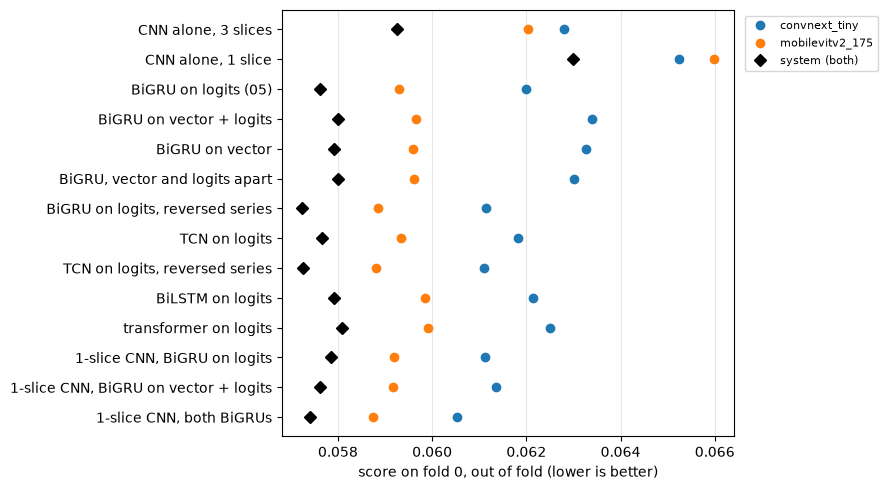

systems: BiGRU on logits (05) 0.0576, 1-slice CNN, both BiGRUs 0.0574 | difference: -0.0002 [-0.0009, +0.0004]


In [3]:
def pair(cx, mv, f=seq_probs, **kw):
    return {"cx": f(cx, **kw), "mv": f(mv, **kw)}


SINGLE = {  # name: the convnext_tiny and mobilevitv2_175 predictions
    "CNN alone, 3 slices": pair("b3_512_convnext_tiny", "b3_512_mobilevitv2_175", cnn_probs),
    "CNN alone, 1 slice": pair("b3_512_convnext_tiny_1x1", "b3_512_mobilevitv2_175_1x1", cnn_probs),
    "BiGRU on logits (05)": pair("is_cx_logits_f0", "is_mv_logits_f0"),
    "BiGRU on vector + logits": pair("e5_convnext_3x1", "e5_mobilevit_3x1_features"),
    "BiGRU on vector": pair("e5_convnext_3x1_featonly", "e5_mobilevit_3x1_featonly"),
    "BiGRU, vector and logits apart": pair("q4_gru_branch_cx_f0", "q4_gru_branch_mv_f0"),
    "BiGRU on logits, reversed series": pair("aug_gru_rev_cx_f0", "aug_gru_rev_mv_f0", tta=True),
    "TCN on logits": pair("q5_tcn_cx_f0", "q5_tcn_mv_f0"),
    "TCN on logits, reversed series": pair("aug_tcn_rev_cx_f0", "aug_tcn_rev_mv_f0", tta=True),
    "BiLSTM on logits": pair("q5_lstm_cx_f0", "q5_lstm_mv_f0"),
    "transformer on logits": pair("q5_transformer_cx_f0", "q5_transformer_mv_f0"),
    "1-slice CNN, BiGRU on logits": pair("is_cx1x1_logits_f0", "is_mv1x1_logits_f0"),
    "1-slice CNN, BiGRU on vector + logits": pair("e5_convnext_1x1", "e5_mobilevit_1x1"),
}
ONE = "1-slice CNN, both BiGRUs"
SINGLE[ONE] = {b: (SINGLE["1-slice CNN, BiGRU on logits"][b] + SINGLE["1-slice CNN, BiGRU on vector + logits"][b]) / 2
               for b in BACKBONES}
for p in SINGLE.values():
    p["late"] = (p["cx"] + p["mv"]) / 2

fig, ax = plt.subplots(figsize=(9, 5))
pos = np.arange(len(SINGLE))[::-1]
for key, label in [("cx", "convnext_tiny"), ("mv", "mobilevitv2_175"), ("late", "system (both)")]:
    ax.plot([score(y, p[key]) for p in SINGLE.values()], pos, "o" if key != "late" else "D", color=COLORS[key], label=label)
ax.set_yticks(pos, list(SINGLE))
ax.set_xlabel("score on fold 0, out of fold (lower is better)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
BASE = "BiGRU on logits (05)"
print(f"systems: {BASE} {score(y, SINGLE[BASE]['late']):.4f}, {ONE} {score(y, SINGLE[ONE]['late']):.4f} | difference:",
      interval(difference(SINGLE[BASE]["late"], SINGLE[ONE]["late"])))

### 2.1 Key findings

- The reference is the BiGRU on logits of 05: 0.0576.
- The 1-slice CNN alone is worse than the 3-slice CNN: +0.0024 for convnext_tiny, +0.0040 for mobilevitv2_175.
- **With a BiGRU on logits it catches up:** for convnext_tiny it beats the 3-slice one (1-slice 0.0611, 3-slice 0.0620), for mobilevitv2_175 it is level (1-slice 0.0592, 3-slice 0.0593).
- A likely reason: the BiGRU reads the neighbouring slices itself, which the 3-slice CNN sees in its input.
- **The 1-slice CNN with both BiGRUs scores 0.0574, level with the reference** (−0.0002 [−0.0009, +0.0004]).
- The other sequence models on the 3-slice CNN lie between 0.0572 (the BiGRU with reversed series, below the threshold of 0.001 in 05) and 0.0581.
- mobilevitv2_175 beats convnext_tiny in every row except the 1-slice CNN alone.

## 3. Ensembles on fold 0

The BiGRU on logits of 05 together with other systems of section 2, with equal weights; the CNNs alone are mixed in with a small weight instead. The difference of each ensemble to the BiGRU on logits alone:

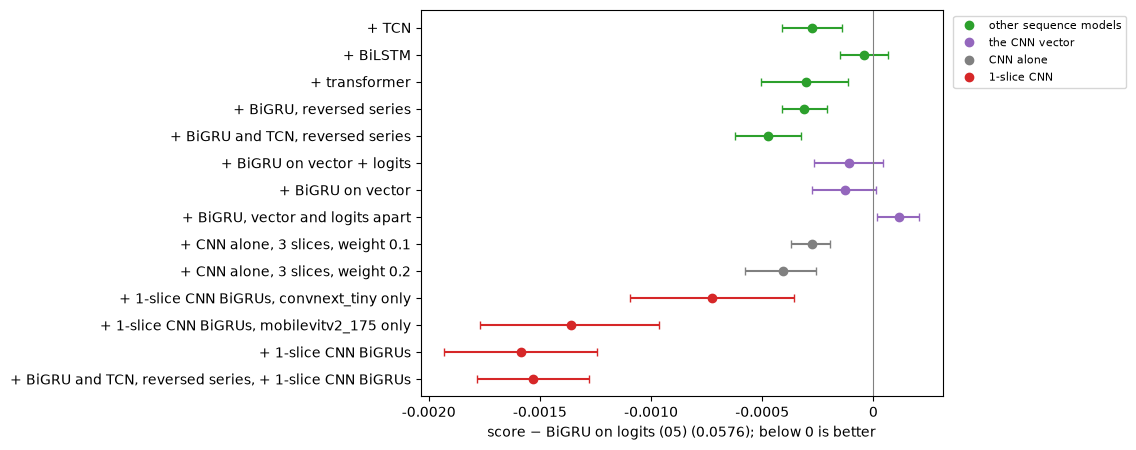

BiGRU on logits (05), mean of the logits instead of the probabilities − mean of the probabilities: +0.0007 [+0.0005, +0.0009]
BiGRU on logits (05) + 1-slice CNN BiGRUs: 0.0560
BiGRU on logits (05) + BiGRU and TCN, reversed series, + 1-slice CNN BiGRUs: 0.0561


the second − the first: +0.0001 [-0.0001, +0.0002]


In [4]:
S = {name: p["late"] for name, p in SINGLE.items()}
base = S[BASE]
mean = lambda *names: np.mean([S[n] for n in names], 0)  # noqa: E731
reversed_two = [BASE, "BiGRU on logits, reversed series", "TCN on logits, reversed series"]  # 05, 4.2
ENSEMBLES = {  # name: (prediction, group)
    "+ TCN": (mean(BASE, "TCN on logits"), "other sequence models"),
    "+ BiLSTM": (mean(BASE, "BiLSTM on logits"), "other sequence models"),
    "+ transformer": (mean(BASE, "transformer on logits"), "other sequence models"),
    "+ BiGRU, reversed series": (mean(BASE, "BiGRU on logits, reversed series"), "other sequence models"),
    "+ BiGRU and TCN, reversed series": (mean(*reversed_two), "other sequence models"),
    "+ BiGRU on vector + logits": (mean(BASE, "BiGRU on vector + logits"), "the CNN vector"),
    "+ BiGRU on vector": (mean(BASE, "BiGRU on vector"), "the CNN vector"),
    "+ BiGRU, vector and logits apart": (mean(BASE, "BiGRU, vector and logits apart"), "the CNN vector"),
    "+ CNN alone, 3 slices, weight 0.1": (0.9 * base + 0.1 * S["CNN alone, 3 slices"], "CNN alone"),
    "+ CNN alone, 3 slices, weight 0.2": (0.8 * base + 0.2 * S["CNN alone, 3 slices"], "CNN alone"),
    "+ 1-slice CNN BiGRUs, convnext_tiny only": (np.mean([base, SINGLE[ONE]["cx"]], 0), "1-slice CNN"),
    "+ 1-slice CNN BiGRUs, mobilevitv2_175 only": (np.mean([base, SINGLE[ONE]["mv"]], 0), "1-slice CNN"),
    "+ 1-slice CNN BiGRUs": (mean(BASE, ONE), "1-slice CNN"),
    "+ BiGRU and TCN, reversed series, + 1-slice CNN BiGRUs": (mean(*reversed_two, ONE), "1-slice CNN"),
}
GROUP_COLORS = {"other sequence models": "tab:green", "the CNN vector": "tab:purple", "CNN alone": "0.5",
                "1-slice CNN": "tab:red"}
d_ens = {name: difference(base, p) for name, (p, _) in ENSEMBLES.items()}
fig, ax = plt.subplots(figsize=(11.5, 4.6))
forest(ax, d_ens, [GROUP_COLORS[g] for _, g in ENSEMBLES.values()])
for g, c in GROUP_COLORS.items():
    ax.plot([], [], "o", color=c, label=g)
ax.set_xlabel(f"score − {BASE} ({score(y, base):.4f}); below 0 is better")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

lg = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))  # noqa: E731
logit_mean = sigmoid((lg(SINGLE[BASE]["cx"]) + lg(SINGLE[BASE]["mv"])) / 2)
print(f"{BASE}, mean of the logits instead of the probabilities − mean of the probabilities:",
      interval(difference(base, logit_mean)))
best = {n: ENSEMBLES[n][0] for n in ["+ 1-slice CNN BiGRUs", "+ BiGRU and TCN, reversed series, + 1-slice CNN BiGRUs"]}
for n, p in best.items():
    print(f"{BASE} {n}: {score(y, p):.4f}")
print("the second − the first:", interval(difference(*best.values())))

### 3.1 Key findings

- The reference is the BiGRU on logits of 05: 0.0576. A negative difference is better.
- **The 1-slice CNN BiGRUs help the most: −0.0016 [−0.0019, −0.0012], score 0.0560.**
- Those of mobilevitv2_175 alone give −0.0014, those of convnext_tiny alone −0.0007.
- A likely reason: they are built on other CNNs. All other members correct the same 3-slice CNNs, so their errors overlap.
- The BiGRU and TCN with reversed series together: −0.0005.
- TCN, transformer or BiGRU with reversed series alone: −0.0003 each.
- BiLSTM: no gain.
- The BiGRUs on the CNN vector: −0.0001 to +0.0001, not beyond noise.
- The CNN alone mixed in with weight 0.1 or 0.2: −0.0003 to −0.0004.
- Averaging logits instead of probabilities is worse: +0.0007.
- Next to the 1-slice CNN BiGRUs, the BiGRU and TCN with reversed series add nothing: 0.0561 against 0.0560. With four members the weight of the 1-slice CNN BiGRUs falls from 1/2 to 1/4, which is part of this result.

## 4. The chosen ensemble

The 1-slice CNNs exist only for fold 0 (trained on folds 1–4); training them for the other four folds would take about 20 hours and was not done. Of the models trained on all five folds, the BiGRU on logits of 05 stays alone. The other sequence models gain at most 0.0005 (section 3); the gain is small (below the decision threshold of 0.001, 04) and they are variations on the same CNNs, so we chose simplicity.

- In one fold: the convnext_tiny and the mobilevitv2_175 CNN each read every slice of a series with its two neighbours and give 6 logits per slice. A BiGRU reads these logits along the whole series and corrects every slice (3 seeds, averaged). The two backbones are averaged.

![One fold: two CNNs, a BiGRU on the logits of each, the mean of the two](figures/06_one_fold.png)

- Over five folds: this is done five times, each time trained without one fold. The test prediction is the mean of 5 folds × 2 backbones × 3 seeds = 30 sequence models (on 10 CNNs).

![Five folds: the one-fold model trained five times, the test prediction is the mean of the five](figures/06_five_folds.png)

- Each fold's models also predict the fold left out. Together these out-of-fold predictions cover every training slice once, which gives our estimate of the score:

In [5]:
from ich.metrics import bootstrap


def fold_run(backbone, fold):
    return f"b3_512_{backbone}" if fold == 0 else f"c_{backbone}_f{fold}"


y_all, g_all, fold_of = [], [], []
p_all = {key: [] for key in ["cnn cx", "cnn mv", "cx", "mv"]}  # the CNN alone and its BiGRU, per backbone
for fold in range(5):
    v = pd.read_csv(FEATURES / fold_run("convnext_tiny", fold) / "oof_images.csv")
    k = v["keep"].to_numpy()
    for b, backbone in BACKBONES.items():
        assert pd.read_csv(FEATURES / fold_run(backbone, fold) / "oof_images.csv")["image"].equals(v["image"])
        p_all[f"cnn {b}"].append(sigmoid(np.load(FEATURES / fold_run(backbone, fold) / "oof_logits.npy"))[k])
        runs = [SEQ / f"is_{b}_logits_f{fold}_s{s}" for s in range(3)]
        for d in runs:
            assert pd.read_csv(d / "val.csv")["image"].equals(v["image"]), d
        p_all[b].append(np.mean([np.load(d / "val_probs.npy") for d in runs], 0)[k])
    y_all.append(position_labels.loc[v["image"][k]].to_numpy())
    g_all.append(table.set_index("image").loc[v["image"][k], "patient"].to_numpy())
    fold_of.append(np.full(k.sum(), fold))
y_all, g_all, fold_of = np.concatenate(y_all), np.concatenate(g_all), np.concatenate(fold_of)
p_all = {key: np.concatenate(p) for key, p in p_all.items()}
p_all["late"] = (p_all["cx"] + p_all["mv"]) / 2

print(f"5-fold out of fold, {len(y_all):,} kept slices")
for key, label in [("cnn cx", "convnext_tiny CNN alone"), ("cnn mv", "mobilevitv2_175 CNN alone"),
                   ("cx", "convnext_tiny BiGRU"), ("mv", "mobilevitv2_175 BiGRU"), ("late", "the chosen ensemble")]:
    r = bootstrap(image_losses(y_all, p_all[key]), g_all)
    print(f"  {label:26s} {r['mean']:.4f} [{r['low']:.4f}, {r['high']:.4f}]")

5-fold out of fold, 745,909 kept slices


  convnext_tiny CNN alone    0.0641 [0.0624, 0.0659]


  mobilevitv2_175 CNN alone  0.0624 [0.0607, 0.0640]


  convnext_tiny BiGRU        0.0635 [0.0617, 0.0654]


  mobilevitv2_175 BiGRU      0.0599 [0.0582, 0.0616]


  the chosen ensemble        0.0586 [0.0569, 0.0603]


The two backbones are averaged with equal weights. Fitted weights were also tried on these out-of-fold predictions (a = mobilevitv2_175, b = convnext_tiny BiGRUs):

- weight: p = w·a + (1 − w)·b;
- regression: logit p = w_a·logit a + w_b·logit b, the same two coefficients for all labels, no intercept;
- regression per label: the same with two coefficients per label.

Each is fitted on four folds and scored on the fifth (cross-fitting), against the equal mean; the coefficients below are fitted on all five folds:

In [6]:
from scipy.optimize import minimize, minimize_scalar

from ich.metrics import label_losses

a, b_ = p_all["mv"], p_all["cx"]


def fit_regression(la, lb, y_, loss):
    return minimize(lambda w: loss(y_, sigmoid(w[0] * la + w[1] * lb)), [0.5, 0.5], method="Nelder-Mead",
                    options={"xatol": 1e-5, "fatol": 1e-8}).x


one_label = lambda y_, p: float(label_losses(y_, p).mean())  # noqa: E731
FITS = {  # name: (fit on the rows i -> coefficients, apply(coefficients, a, b) -> p)
    "weight": (lambda i: minimize_scalar(lambda w: score(y_all[i], w * a[i] + (1 - w) * b_[i]), bounds=(0, 1),
                                         method="bounded").x,
               lambda w, pa, pb: w * pa + (1 - w) * pb),
    "regression": (lambda i: fit_regression(lg(a[i]), lg(b_[i]), y_all[i], score),
                   lambda w, pa, pb: sigmoid(w[0] * lg(pa) + w[1] * lg(pb))),
    "regression per label": (lambda i: np.array([fit_regression(lg(a[i][:, j]), lg(b_[i][:, j]), y_all[i][:, j], one_label)
                                                 for j in range(len(LABELS))]),
                             lambda w, pa, pb: sigmoid(w[:, 0] * lg(pa) + w[:, 1] * lg(pb))),
}
W = {}  # name: the coefficients fitted on all five folds, used for the test in section 5
for name, (fit, apply) in FITS.items():
    cross = np.zeros_like(a)
    for fold in range(5):
        cross[fold_of == fold] = apply(fit(fold_of != fold), a[fold_of == fold], b_[fold_of == fold])
    d = paired_bootstrap(image_losses(y_all, p_all["late"]), image_losses(y_all, cross), g_all)
    w = W[name] = fit(np.ones(len(a), bool))
    coef = (f"w_a {w:.3f}, w_b {1 - w:.3f}" if name == "weight" else
            f"w_a {w[0]:.3f}, w_b {w[1]:.3f}, sum {w.sum():.3f}" if name == "regression" else
            f"sum of the two {w.sum(1).min():.2f}–{w.sum(1).max():.2f}, a share {(w[:, 0] / w.sum(1)).min():.2f}–{(w[:, 0] / w.sum(1)).max():.2f}")
    print(f"{name:21s} {score(y_all, cross):.4f} | − equal: {interval(d)} | {coef}")

weight                0.0584 | − equal: -0.0002 [-0.0002, -0.0001] | w_a 0.639, w_b 0.361


regression            0.0572 | − equal: -0.0015 [-0.0017, -0.0012] | w_a 0.494, w_b 0.312, sum 0.806


regression per label  0.0571 | − equal: -0.0015 [-0.0017, -0.0013] | sum of the two 0.78–0.85, a share 0.56–0.66


### 4.1 Key findings

- **Our estimate for the chosen ensemble: 0.0586 [0.0569, 0.0603]** (5-fold out of fold, pooled from the held-out folds).
- The CNNs alone: mobilevitv2_175 0.0624, convnext_tiny 0.0641.
- The BiGRU of one backbone: mobilevitv2_175 0.0599, convnext_tiny 0.0635. Their mean beats both.
- The score is lower on fold 0 (0.0576) than over the five folds.
- **A fitted weight gains −0.0002, far below the decision threshold of 0.001** (0.64 for mobilevitv2_175).
- The regressions gain −0.0015, beyond the threshold, but their coefficients sum to about 0.8: besides weighting, they soften the predictions like a temperature of about 1.25 fitted out of fold.
- In 05 a temperature may only come from a model's own training folds (05, 6), so the regressions are not allowed; their weighting alone is the fitted weight above.
- Equal weights stay.
- The test prediction averages five such fold models, so its score is not this one; section 5 gives it.

## 5. Submission scores

The steps to the chosen ensemble, each on all five folds, predict the test set: the CNNs alone, each backbone's CNN with its BiGRU, and the chosen ensemble, without and with the temperature of 05 (6); below them, the fitted weights of section 4. The test is the stage-2 test of Kaggle, labelled by three readers; the score is the private one. Nothing above was chosen on it.

The files are written here, apart from the final file of 05 (with the temperature):

In [7]:
from ich.submission import check_submission, to_submission

test_images = pd.read_csv(FEATURES / "b3_512_convnext_tiny" / "test_images.csv")["image"]
sample = pd.read_csv(paths["raw_data_dir"] / "stage_2_sample_submission.csv")


def test_cnn(backbone):
    # Mean probability of the five CNNs of one backbone on the test set.
    runs = [FEATURES / fold_run(backbone, fold) for fold in range(5)]
    for d in runs:
        assert pd.read_csv(d / "test_images.csv")["image"].equals(test_images), d
    return np.mean([sigmoid(np.load(d / "test_logits.npy")) for d in runs], 0)


def test_bigru(b):
    # Mean probability of the 5 folds × 3 seeds BiGRUs of one backbone on the test set.
    runs = [SEQ / f"is_{b}_logits_f{fold}_s{s}" for fold in range(5) for s in range(3)]
    for d in runs:
        assert pd.read_csv(d / "test.csv")["image"].equals(test_images), d
    return np.mean([np.load(d / "test_probs.npy") for d in runs], 0)


test_a, test_b = test_bigru("mv"), test_bigru("cx")  # a and b of section 4
FILES = {f"06_cnn5_{backbone}": test_cnn(backbone) for backbone in BACKBONES.values()}
FILES["06_cnn10"] = (FILES["06_cnn5_convnext_tiny"] + FILES["06_cnn5_mobilevitv2_175"]) / 2  # the CNNs of 04
FILES |= {"06_bigru5_convnext_tiny": test_b, "06_bigru5_mobilevitv2_175": test_a,
          "06_bigru10": (test_a + test_b) / 2}  # the chosen ensemble
for name, file in [("weight", "06_ab_weight"), ("regression", "06_ab_regression"),
                   ("regression per label", "06_ab_regression_label")]:  # the fitted weights of section 4
    FILES[file] = FITS[name][1](W[name], test_a, test_b)
for name, p in FILES.items():
    submission = check_submission(to_submission(test_images, p), sample)
    submission.to_csv(OUTPUTS / "submissions" / f"{name}.csv.gz", index=False, float_format="%.6f")
    print(f"{name}.csv.gz: {len(submission):,} rows")

06_cnn5_convnext_tiny.csv.gz: 727,392 rows


06_cnn5_mobilevitv2_175.csv.gz: 727,392 rows


06_cnn10.csv.gz: 727,392 rows


06_bigru5_convnext_tiny.csv.gz: 727,392 rows


06_bigru5_mobilevitv2_175.csv.gz: 727,392 rows


06_bigru10.csv.gz: 727,392 rows


06_ab_weight.csv.gz: 727,392 rows


06_ab_regression.csv.gz: 727,392 rows


06_ab_regression_label.csv.gz: 727,392 rows


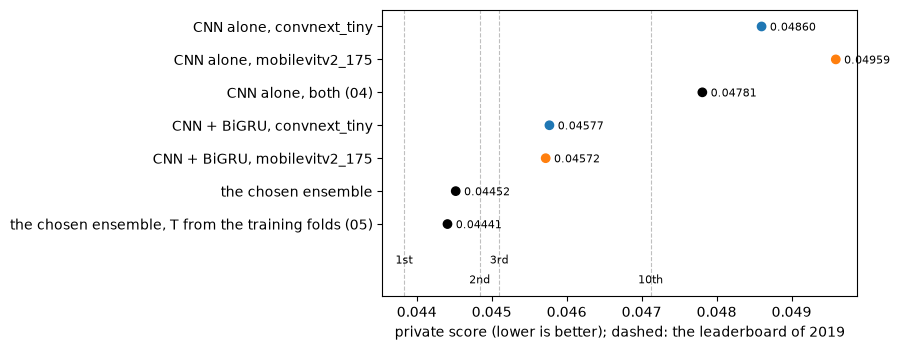

the fitted weights of section 4 instead of equal weights (0.04452): weight 0.04464, regression 0.04770, regression per label 0.04747


In [8]:
SUBMITTED = [  # (row, file, private score)
    ("CNN alone, convnext_tiny", "06_cnn5_convnext_tiny", 0.04860),
    ("CNN alone, mobilevitv2_175", "06_cnn5_mobilevitv2_175", 0.04959),
    ("CNN alone, both (04)", "06_cnn10", 0.04781),
    ("CNN + BiGRU, convnext_tiny", "06_bigru5_convnext_tiny", 0.04577),
    ("CNN + BiGRU, mobilevitv2_175", "06_bigru5_mobilevitv2_175", 0.04572),
    ("the chosen ensemble", "06_bigru10", 0.04452),
    ("the chosen ensemble, T from the training folds (05)", "05_seq10_bigru_T", 0.04441),
]
s = [(row, v) for row, _, v in SUBMITTED][::-1]
colors = [COLORS["cx"] if "convnext" in r else COLORS["mv"] if "mobilevit" in r else COLORS["late"] for r, _ in s]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter([v for _, v in s], np.arange(len(s)), c=colors, zorder=3)
for i, (_, v) in enumerate(s):
    ax.annotate(f"{v:.5f}", (v, i), xytext=(6, -3), textcoords="offset points", fontsize=8)
for i, (place, v) in enumerate({"1st": 0.04383, "2nd": 0.04484, "3rd": 0.04510, "10th": 0.04712}.items()):
    ax.axvline(v, color="0.75", ls="--", lw=0.8)
    ax.text(v, -1.2 - 0.6 * (i % 2), place, fontsize=8, ha="center")
ax.set_ylim(-2.2, len(s) - 0.5)
ax.set_yticks(np.arange(len(s)), [r for r, _ in s])
ax.set_xlabel("private score (lower is better); dashed: the leaderboard of 2019")
plt.tight_layout()
plt.show()

FITTED = {"weight": 0.04464, "regression": 0.04770, "regression per label": 0.04747}  # files 06_ab_*
print("the fitted weights of section 4 instead of equal weights (0.04452):",
      ", ".join(f"{name} {v:.5f}" for name, v in FITTED.items()))

### 5.1 Key findings

- **The chosen ensemble scores 0.04452, with the temperature of 05 0.04441:** between the 1st (0.04383) and the 2nd place (0.04484) of 2019.
- The target of the project, the 10th place (0.04712), is reached. These are late submissions, not ranks of the competition.
- The CNNs alone: convnext_tiny 0.04860, mobilevitv2_175 0.04959, their mean 0.04781.
- The BiGRU is the largest step: −0.0028 for convnext_tiny (0.04577), −0.0039 for mobilevitv2_175 (0.04572).
- One backbone with its BiGRU already lies between the 5th (0.04561) and the 6th place (0.04586).
- Averaging the two backbones gains another −0.0012 (0.04572 → 0.04452).
- The temperature adds −0.0001.
- The fitted weights of section 4 are all worse than equal weights: 0.04464, 0.04770, 0.04747 against 0.04452.
- **Softer predictions help out of fold and hurt on the test:** the regressions (like T ≈ 1.25) gain −0.0015 out of fold and lose +0.003 on the test, while the sharper T = 0.85 of 05 gained on the test (0.04402). A likely reason: one reader labelled the training set, three the test set.
- The steps rank on the test as out of fold: CNN alone, then CNN + BiGRU, then the ensemble.
- The backbones do not: out of fold mobilevitv2_175 is clearly better (CNN 0.0624 against 0.0641, with BiGRU 0.0599 against 0.0635). On the test its CNN is worse and its BiGRU level.

## Summary

- **Choices made** (on fold 0 out of fold, against the BiGRU on logits of 05, 0.0576, unless noted):

  | Question | Tested | Chosen | Result of the others |
  |---|---|---|---|
  | other sequence models next to the BiGRU | TCN, BiLSTM, transformer, BiGRU and TCN with reversed series | none | at most −0.0005 (BiGRU and TCN, reversed series); below the threshold of 0.001, and variations on the same CNNs |
  | the CNN vector | BiGRU on vector, on vector + logits, the two apart | none | −0.0001 to +0.0001, not beyond noise |
  | the CNN alone in the mix | weight 0.1 and 0.2 | none | −0.0003 to −0.0004 |
  | how to average | probabilities, logits | probabilities | logits +0.0007 |
  | the 1-slice CNNs | a BiGRU on logits and on vector + logits, both backbones | not trained on five folds (about 20 hours) | the best on fold 0 (−0.0016, score 0.0560), the only member beyond the threshold |
  | weights of the two backbones (five folds, cross-fitted) | equal; a weight; a logistic regression on the logits, shared and per label | equal | the weight −0.0002, below the threshold; the regressions −0.0015, but they also fit a temperature out of fold, which the rule of 05 does not allow. On the test all worse: 0.04464, 0.04770, 0.04747 against 0.04452 |

- **The chosen ensemble is the one of 05:** a BiGRU on the logits of each 3-slice CNN, 3 seeds, the mean of the two backbones and the five folds.
- **Five folds:** 0.0586 [0.0569, 0.0603] out of fold.
- **Test set:** the CNNs alone 0.04781, one backbone with its BiGRU 0.04572–0.04577, the chosen ensemble 0.04452, with the temperature of 05 0.04441 (between the 1st, 0.04383, and the 2nd place, 0.04484, of 2019).

**Limits**
- The members were compared on fold 0 only; the gain of the 1-slice CNNs is not measured on five folds.
- Fold 0, where the members were chosen, is also one of the five folds of section 4, so the five-fold out-of-fold score is slightly optimistic.
- Equal weights were kept by the threshold and the temperature rule of 05; the test scores of the fitted weights were seen too and agree.
- Out of fold mobilevitv2_175 is the clearly better backbone, on the test it is not: the out-of-fold score ranks the steps right but not the backbones.